<a href="https://colab.research.google.com/github/madeeha-noor/Student-Success-Early-Warning/blob/main/notebooks/02_data_quality_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q ucimlrepo

In [2]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ds = fetch_ucirepo(id = 697)
df = pd.concat([ds.data.features, ds.data.targets], axis = 1)
df.columns = df.columns.str.strip()
print(df.shape)

(4424, 37)


## Data-Quality report

In [3]:
print("Missing values:", df.isna(). sum(). sum())
print("Duplicate rows:", df.duplicated(). sum())
df.describe().T

Missing values: 0
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
Marital Status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application mode,4424.0,18.669078,17.484682,1.00,1.00,17.000000,39.000000,57.000000
Application order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,8856.642631,2063.566416,33.00,9085.00,9238.000000,9556.000000,9991.000000
Daytime/evening attendance,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous qualification,4424.0,4.577758,10.216592,1.00,1.00,1.000000,1.000000,43.000000
Previous qualification (grade),4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
Nacionality,4424.0,1.873192,6.914514,1.00,1.00,1.000000,1.000000,109.000000
Mother's qualification,4424.0,19.561935,15.603186,1.00,2.00,19.000000,37.000000,44.000000
Father's qualification,4424.0,22.275316,15.343108,1.00,3.00,19.000000,37.000000,44.000000


## Summary Statistics: what i noticed
- All 36 feature columns have 4,424 vaues, so there are no missing values
- olumns such as Course, Martial Status, Application mode, Nacionality and the parents' qualiffication / occupation are category codes, not real quantites. We will decode them and treat them as categories
- Age at enrollment is skewed: median 20, maximum 70
- Ciurricular unit counts have maximums far above the 75th percentile (e.g: 1st sem evaluations: 75% = 10, max = 45), so they are possible outliers
- Grades column have a minimum of 0. We still need to check whether these are students with no units, not real zero scores

In [4]:
for sem in ["1st", "2nd"]:
  enrolled = df[f"Curricular units {sem} sem (enrolled)"]
  grade = df[f"Curricular units {sem} sem (grade)"]
  print(f"{sem} sem -> 0 units enrolled: {(enrolled == 0).sum()}, grade is 0:{(grade == 0).sum()}, both: {((enrolled == 0) & (grade == 0)).sum()}")

1st sem -> 0 units enrolled: 180, grade is 0:718, both: 180
2nd sem -> 0 units enrolled: 180, grade is 0:870, both: 180


In [5]:
df.nunique().sort_values()

,0
Daytime/evening attendance,2
Displaced,2
Debtor,2
Educational special needs,2
International,2
Scholarship holder,2
Gender,2
Tuition fees up to date,2
Target,3
Marital Status,6


In [6]:
zero_both = df[(df["Curricular units 1st sem (enrolled)"] == 0) & (df["Curricular units 2nd sem (enrolled)"] == 0)]
print("Students with 0 units in BOTH semesters:", len(zero_both))
print(zero_both["Target"].value_counts())

Students with 0 units in BOTH semesters: 180
Target
Dropout     77
Graduate    75
Enrolled    28
Name: count, dtype: int64


In [7]:
for sem in ["1st", "2nd"]:
  enr = df[f"Curricular units {sem} sem (enrolled)"]
  gr = df[f"Curricular units {sem} sem (grade)"]
  sub = df[(enr > 0) & (gr == 0)]
  print(f"{sem} sem: enrolled but grade 0 = {len(sub)}; "
        f"With 0 evaluations = {(sub[f"Curricular units {sem} sem (evaluations)"] == 0).sum()}; "
        f"With 0 approved = {(sub[f"Curricular units {sem} sem (approved)"] == 0).sum()}")

1st sem: enrolled but grade 0 = 538; With 0 evaluations = 169; With 0 approved = 538
2nd sem: enrolled but grade 0 = 690; With 0 evaluations = 221; With 0 approved = 690


In [8]:
c1 = zero_both["Curricular units 1st sem (credited)"]
c2 = zero_both["Curricular units 2nd sem (credited)"]
print("Zero-unit students with some credited units:", ((c1 > 0) | (c2 > 0)).sum())

Zero-unit students with some credited units: 0


In [9]:
for sem in ["1st", "2nd"]:
  enr = df[f"Curricular units {sem} sem (enrolled)"]
  app = df[f"Curricular units {sem} sem (approved)"]
  ev = df[f"Curricular units {sem} sem (evaluations)"]
  print(f"{sem} sem: approved > enrolled: {(app > enr).sum()}, "
        f"approved > evaluations: {(app > ev).sum()}, "
        f"evaluations > 0 but enrolled == 0: {((ev > 0) & (enr == 0)).sum()}")

1st sem: approved > enrolled: 0, approved > evaluations: 0, evaluations > 0 but enrolled == 0: 0
2nd sem: approved > enrolled: 0, approved > evaluations: 0, evaluations > 0 but enrolled == 0: 0


## Zero-unit students and logic checks
- 180 students enrolled in 0 units in both semester. Their outcomes are Dropout 77, Graduate 75 and Enrolled 28, so zero units does not always mean dropout
- None of these 180 students has credited units, so recognised credits do not explain why 75 of them graduated. The data doesn not expalin this. We keep these students (4% of the data, including 77 dropouts) and list it as a limitation
- In semester 1, 538 students enrolled in units but have grade 0 (169 took no exams, 369 took exams but passed none). In semester 2 the numbers are 690, 221 and 469. A grade of 0 therefore means "no units passed", not an error, so we keep them
- Logic checks found no inconsistencies: no student has more approved than enrolled units, more approved than evaluations,or evaluations without enrollment
- Inflation, Unemployment and GDP have only 9-10 distinct values accros 4,424 students, so they are national values per period, not student-level values

In [10]:
cols = ['Age at enrollment', 'Admission grade', 'Previous qualification (grade)',
        'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)',
        'Curricular units 1st sem (approved)', 'Curricular units 2nd sem (enrolled)',
        'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)']

rows = []
for col in cols:
  q1 = df[col].quantile(0.25)
  q3 = df[col].quantile(0.75)
  iqr = q3 - q1
  low = q1 - 1.5 * iqr
  high = q3 + 1.5 * iqr
  n_out = ((df[col] < low) | (df[col] > high)).sum()
  rows.append([col, low, high, n_out, round(100 * n_out / len(df), 1)])

pd.DataFrame(rows, columns=['Column', 'Lower limit', 'Upper limit', 'Outliers', '% of students'])

,Column,Lower limit,Upper limit,Outliers,% of students
0,Age at enrollment,10.00,34.00,441,10.0
1,Admission grade,92.55,160.15,86,1.9
2,Previous qualification (grade),102.50,162.50,179,4.0
3,Curricular units 1st sem (enrolled),2.00,10.00,424,9.6
4,Curricular units 1st sem (evaluations),0.00,16.00,158,3.6
5,Curricular units 1st sem (approved),-1.50,10.50,180,4.1
6,Curricular units 2nd sem (enrolled),2.00,10.00,369,8.3
7,Curricular units 2nd sem (evaluations),0.00,16.00,109,2.5
8,Curricular units 2nd sem (approved),-4.00,12.00,44,1.0


## Outliers
- We used the IQR rule (values bayond 1.5 x IQR from the quartiles). The most flagged column is Age at enrollment: 441 students (10.0%) are above 34
- Curricular unit counts are also flageed for 8-10% of students (1st sem enrolled 424, 2nd sem enrolled 369)
- These are real, plausible values(mature students, heavy course loads), not errors, so we keep them. Tree-based models are robust to them, and we'll use robust scaling for the other models

In [11]:
codes = ['Marital Status', 'Application mode', 'Course', 'Previous qualification',
         'Nacionality', "Mother's qualification", "Father's qualification",
         "Mother's occupation", "Father's occupation"]

for c in codes:
  text = ds.variables.loc[ds.variables['name'] == c, 'description'].values[0]
  print(c, '->', text, '\n')

Marital Status -> 1 – single 2 – married 3 – widower 4 – divorced 5 – facto union 6 – legally separated 

Application mode -> 1 - 1st phase - general contingent 2 - Ordinance No. 612/93 5 - 1st phase - special contingent (Azores Island) 7 - Holders of other higher courses 10 - Ordinance No. 854-B/99 15 - International student (bachelor) 16 - 1st phase - special contingent (Madeira Island) 17 - 2nd phase - general contingent 18 - 3rd phase - general contingent 26 - Ordinance No. 533-A/99, item b2) (Different Plan) 27 - Ordinance No. 533-A/99, item b3 (Other Institution) 39 - Over 23 years old 42 - Transfer 43 - Change of course 44 - Technological specialization diploma holders 51 - Change of institution/course 53 - Short cycle diploma holders 57 - Change of institution/course (International) 

Course -> 33 - Biofuel Production Technologies 171 - Animation and Multimedia Design 8014 - Social Service (evening attendance) 9003 - Agronomy 9070 - Communication Design 9085 - Veterinary Nursin

In [12]:
import re
def parse_codes(text):
  """Turn '1 - single 2 - married ...' into {1: 'single, 2: 'married, ...}"""
  parts = re.split(r'(?:^|\s)(\d+)\s*[^\w\s]\s+', ' ' + text.strip())
  return {int(parts[i]): parts[i + 1].strip().rstrip(';').strip() for i in range(1, len(parts), 2)}

dfe = df.copy()
dfe = dfe.rename(columns={'Nacionality': 'Nationality'})

code_cols = ['Marital Status', 'Application mode', 'Course', 'Previous qualification',
         'Nacionality', "Mother's qualification", "Father's qualification",
         "Mother's occupation", "Father's occupation"]

for c in code_cols:
  text = ds.variables.loc[ds.variables['name'] == c, 'description'].values[0]
  mapping = parse_codes(text)
  new_name = 'Nationality' if c == 'Nacionality' else c
  dfe[new_name] = df[c].map(mapping)
  print(f"{new_name}: {dfe[new_name].isna().sum()} unmapped values")

Marital Status: 0 unmapped values
Application mode: 0 unmapped values
Course: 0 unmapped values
Previous qualification: 0 unmapped values
Nationality: 0 unmapped values
Mother's qualification: 0 unmapped values
Father's qualification: 0 unmapped values
Mother's occupation: 0 unmapped values
Father's occupation: 0 unmapped values


In [13]:
for c in ['Displaced', 'Educational special needs', 'Debtor',
          'Tuition fees up to date', 'Scholarship holder', 'International']:
          dfe[c] = df[c].map({1: 'Yes', 0: 'No'})

dfe['Gender'] = df['Gender'].map({1: 'Male', 0: 'Female'})
dfe['Daytime/evening attendance'] = df['Daytime/evening attendance'].map({1: 'Daytime', 0: 'Evening'})
dfe[['Marital Status', 'Course', 'Nationality', 'Debtor', 'Gender', 'Target']].head()

,Marital Status,Course,Nationality,Debtor,Gender,Target
0,single,Animation and Multimedia Design,Portuguese,No,Male,Dropout
1,single,Tourism,Portuguese,No,Male,Graduate
2,single,Communication Design,Portuguese,No,Male,Dropout
3,single,Journalism and Communication,Portuguese,No,Female,Graduate
4,married,Social Service (evening attendance),Portuguese,No,Female,Graduate


## Decoding category codes
- Nine columns (Marital Status, Application mode, Course, Previous qualification, Nationality, and the mother's and father's qualification and occupation) store category codes as numbers, so averages or correlations on them would be meaningless
- We decoded them with the labels from the dataset's own dictionary into a readable copy (dfe). Unmapped values: 0 for all nine columns
- We also decoded the yes/no columns, Gender and Daytime/evening attendance, and renamed the typo column Nacionality to Nationality in the copy
- The original numeric table (df) is kept for modelling, where the codes will be one-hot encoded

## Data-quality decisons
- Missing values: 0, no action needed
- Duplicate rows: 0, no action needed
- Category codes decoded into a readable copy (dfe); numeric table kept for modelling
- Typo column Nacionality renamed to Nationality in the copy
- 180 students with zero: units kept, listed as a limitations
- Enrolled but grade 0 (538 and 690 students): kept, it means no unit passed
- Logic errors: 0, no action needed
- Outliers(up to 10% students): kept, robust scaling later
- Economic columns: national values, not student level, so flagged
- Class imbalance (50/32/18%): handled later with stratified CV, class weights and macro-F1
- Possible leakage (fee status, 2nd-semester data): to be checked later

## Exploratory data analysis

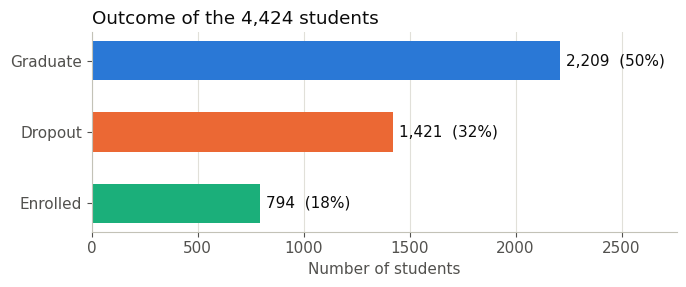

In [14]:
COLORS = {'Graduate': '#2a78d6', 'Dropout': '#eb6834', 'Enrolled': '#1baf7a'}
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e1e0d9'

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': MUTED,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'font.size': 11})

order = ['Graduate', 'Dropout', 'Enrolled']
counts = dfe['Target'].value_counts()[order]

fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.barh(order, counts.values, color=[COLORS[o] for o in order], height=0.55)
ax.invert_yaxis()
for bar, c in zip(bars, counts.values):
    ax.text(c + 30, bar.get_y() + bar.get_height() / 2,
            f"{c:,}  ({c / len(dfe):.0%})", va='center', color=INK)
ax.set_xlim(0, counts.max() * 1.25)
ax.set_title(f"Outcome of the {len(dfe):,} students", loc='left', color=INK)
ax.set_xlabel('Number of students')
ax.grid(axis='x', color=GRID)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## Outcome balance
- Of the 4424 students, 2209 (50%) graduated, 1421 (32%) dropped out and 794 (18%) are still enrolled
- The classes are imbalanced, so accuaracy alone would be misleading. We wil use macro-F1 and class weights. "Enrolled" is expected to be the hardest class becuase thses students have no final outcomes yey

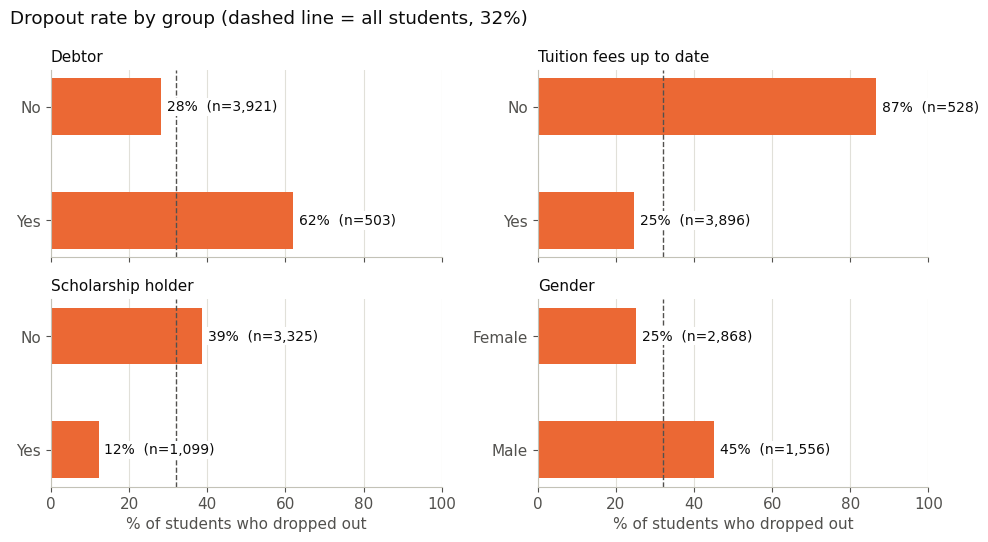

In [15]:
overall = (dfe['Target'] == 'Dropout').mean() * 100
factors = ['Debtor', 'Tuition fees up to date', 'Scholarship holder', 'Gender']

fig, axes = plt.subplots(2, 2, figsize=(10, 5.5), sharex=True)
for ax, f in zip(axes.ravel(), factors):
    g = dfe.groupby(f)['Target'].agg(n='size', rate=lambda s: (s == 'Dropout').mean() * 100)
    ax.barh(g.index.astype(str), g['rate'], color=COLORS['Dropout'], height=0.5)
    ax.invert_yaxis()
    for i, (grp, row) in enumerate(g.iterrows()):
        ax.text(row['rate'] + 1.5, i, f"{row['rate']:.0f}%  (n={int(row['n']):,})",
                va='center', color=INK, fontsize=10,
                bbox=dict(facecolor='white', edgecolor='none', pad=1.5), zorder=3)
    ax.axvline(overall, color=MUTED, linestyle='--', linewidth=1)
    ax.set_title(f, loc='left', color=INK, fontsize=11)
    ax.set_xlim(0, 100)
    ax.grid(axis='x', color=GRID)
    ax.set_axisbelow(True)
for ax in axes[1]:
    ax.set_xlabel('% of students who dropped out')
fig.suptitle(f"Dropout rate by group (dashed line = all students, {overall:.0f}%)",
             x=0.01, ha='left', color=INK)
plt.tight_layout()
plt.show()

## Dropout rate by group
- The overall dropout rate is 32%
- Debrtors drop out far more often than non-debtors(62% vs 28%)
- Students whose tuition fees are not up to date drop oiut at 87%, compared with 25% for students who are up to date
- Scholarship holders drop out less (12%) than students without a scholarship (39%)
- Male students drop out more often than female students (45% vs 25%)
- These are patterns, not proof of cause. For example, the gender gap may reflect differences in the courses students choose. Fee status may also partly be a consequence of leaving, since a student who has left may stop paying, so we will examine it in the leakage check. A hypothesis test will check these differences formally

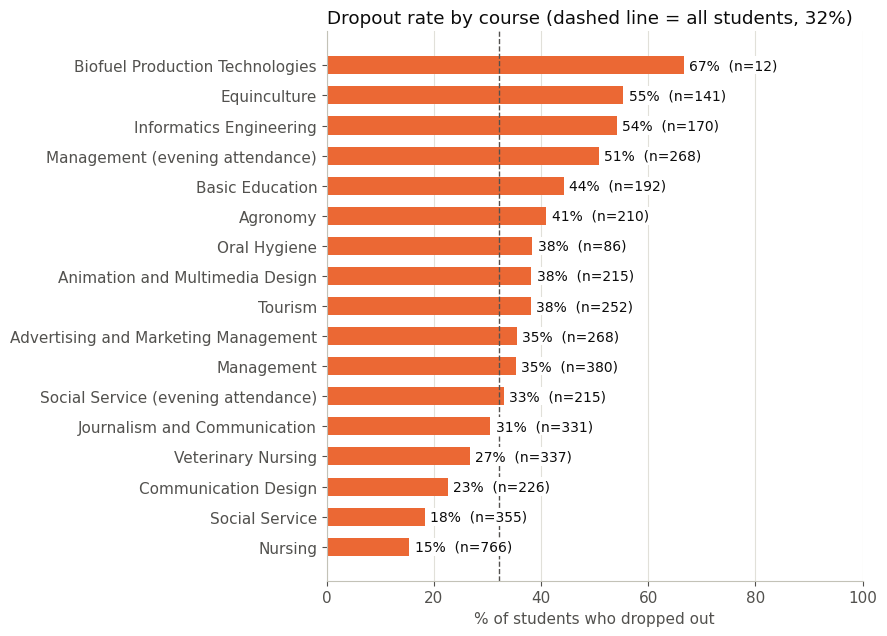

In [16]:
overall = (dfe['Target'] == 'Dropout').mean() * 100

g = (dfe.groupby('Course')['Target']
        .agg(n='size', rate=lambda s: (s == 'Dropout').mean() * 100)
        .sort_values('rate', ascending=False))

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(g.index, g['rate'], color=COLORS['Dropout'], height=0.6)
ax.invert_yaxis()
for i, (course, row) in enumerate(g.iterrows()):
    ax.text(row['rate'] + 1, i, f"{row['rate']:.0f}%  (n={int(row['n']):,})",
            va='center', color=INK, fontsize=10,
            bbox=dict(facecolor='white', edgecolor='none', pad=1.5), zorder=3)
ax.axvline(overall, color=MUTED, linestyle='--', linewidth=1)
ax.set_xlim(0, 100)
ax.set_xlabel('% of students who dropped out')
ax.set_title(f"Dropout rate by course (dashed line = all students, {overall:.0f}%)",
             loc='left', color=INK)
ax.grid(axis='x', color=GRID)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## Dropout rate by course
- ropout rates differ widely between courses, from 15% (Nursing, the largest course with 766 students) and 18% (Social Service) to 54-55% (Informatics Engineering, Equinculture) and 51% (Management, evening attendance)
- Biofuel Production Technologies shows 67%, but it has only 12 students, so this figure is unreliable
- Both evening courses have higher dropout than their daytime counterparts: Management 51% (evening) vs 35% (day), and Social Service 33% (evening) vs 18% (day)
- Course looks like an informative feature, but these are associations. Differences between courses may reflect other factors, such as student background

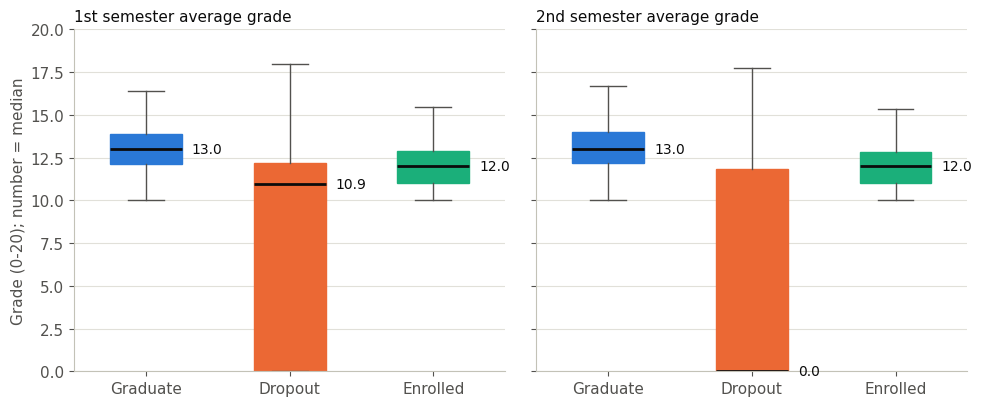

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, sem in zip(axes, ['1st', '2nd']):
    col = f'Curricular units {sem} sem (grade)'
    data = [dfe.loc[dfe['Target'] == o, col] for o in order]
    bp = ax.boxplot(data, patch_artist=True, widths=0.5, showfliers=False,
                    medianprops=dict(color=INK, linewidth=2),
                    whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
    for box, o in zip(bp['boxes'], order):
        box.set_facecolor(COLORS[o])
        box.set_edgecolor(COLORS[o])
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(order)
    for i, d in enumerate(data):
        ax.text(i + 1.32, d.median(), f"{d.median():.1f}", va='center', color=INK, fontsize=10)
    ax.set_ylim(0, 20)
    ax.set_title(f"{sem} semester average grade", loc='left', color=INK, fontsize=11)
    ax.grid(axis='y', color=GRID)
    ax.set_axisbelow(True)
axes[0].set_ylabel('Grade (0-20); number = median')
plt.tight_layout()
plt.show()

## Semester grade by Outcome
- In the first semester, graduates have a median grade of 13.0 with a narrow spread, enrolled students 12.0, and dropouts 10.9. The dropout spread is very wide: at least a quarter of dropouts have a grade of 0, while others have normal grades
- In the second semester the median grade of dropouts is 0.0, so at least half of the dropouts have a second-semester grade of 0, compared with medians of 13.0 (graduates) and 12.0 (enrolled)
- First-semester performance already separates the outcomes, which supports our question "how early can we tell?". Second-semester data arrives later and is partly a result of students leaving, so we will treat it carefully in the leakage check

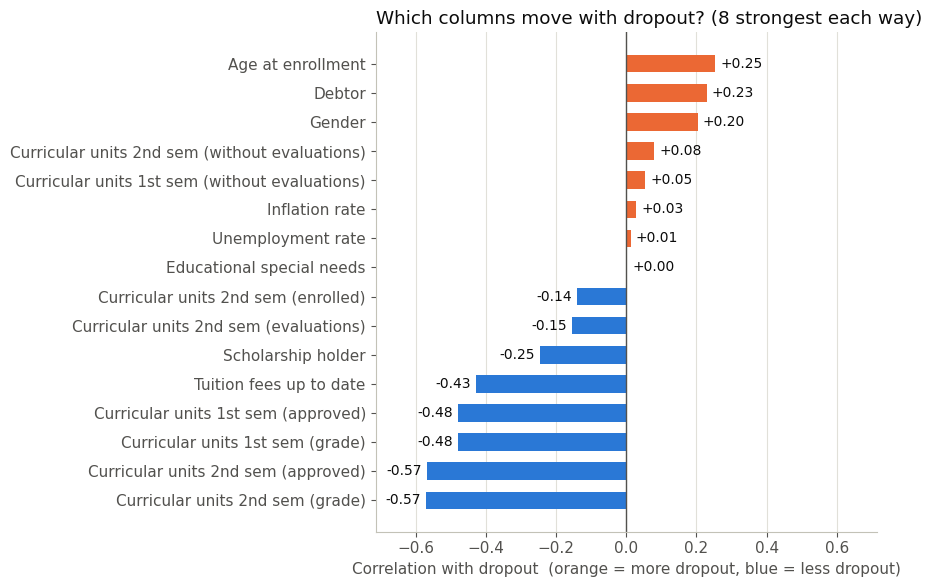

In [18]:
code_columns = ['Marital Status', 'Application mode', 'Course', 'Previous qualification',
                'Nacionality', "Mother's qualification", "Father's qualification",
                "Mother's occupation", "Father's occupation"]
features = df.drop(columns=['Target'] + code_columns)
is_dropout = (df['Target'] == 'Dropout').astype(int)
corr = features.corrwith(is_dropout).sort_values()
top = pd.concat([corr.head(8), corr.tail(8)])

fig, ax = plt.subplots(figsize=(9, 6))
colors = [COLORS['Graduate'] if v < 0 else COLORS['Dropout'] for v in top.values]
ax.barh(top.index, top.values, color=colors, height=0.6)
lim = max(abs(top.values)) * 1.25
gap = lim * 0.02
for i, v in enumerate(top.values):
    ax.text(v + (gap if v >= 0 else -gap), i, f"{v:+.2f}", va='center',
            ha='left' if v >= 0 else 'right', color=INK, fontsize=10)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_xlim(-lim, lim)
ax.set_xlabel('Correlation with dropout  (orange = more dropout, blue = less dropout)')
ax.set_title('Which columns move with dropout? (8 strongest each way)', loc='left', color=INK)
ax.grid(axis='x', color=GRID)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## Which columns move with Dropout
- Correlation is measured between each numeric column and a 0/1 "dropped out" flag. Blue bars mean less dropout, orange bars mean more
- The strongest links are academic: second-semester grade and approved units (-0.57), then first-semester approved units and grade (-0.48). Students who pass more units drop out less
- Tuition fees up to date (-0.43) and scholorship holder (-0.25) point to less dropout. Age at enrollment (+0.25), debtor (+0.23) and male gender (+0.20) point to more dropout
- Inflation, unemployment and special needs are close to 0, so they are weak linear predictors
- Correlation only shows linear links and is not cause. Second semester columns arrive late and partly result from leaving, so they are a leakage risk. The first-semester columns matter most for our "how early" question

In [19]:
from scipy.stats import chi2_contingency

def dropout_test(factor):
  outcome = np.where(dfe['Target'] == 'Dropout', 'Dropout', 'Not dropout')
  table = pd.crosstab(dfe[factor], outcome)
  chi2, p, dof, expected = chi2_contingency(table)
  cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
  return table, p, cramers_v

table, p, v = dropout_test("Tuition fees up to date")
print(table)
print(f"\nchi-square p-value: {p:.3g}")
print(f"Effect size (Cramer's V): {v:.2f}")

col_0                    Dropout  Not dropout
Tuition fees up to date                      
No                           457           71
Yes                          964         2932

chi-square p-value: 1.37e-178
Effect size (Cramer's V): 0.43


In [20]:
rows = []
for f in ['Debtor', 'Tuition fees up to date', 'Scholarship holder', 'Gender']:
    _, p, v = dropout_test(f)
    rows.append([f, p, round(v, 2)])
pd.DataFrame(rows, columns=['Factor', 'p-value', "Cramer's V"])

,Factor,p-value,Cramer's V
0,Debtor,3.134874e-52,0.23
1,Tuition fees up to date,1.373782e-178,0.43
2,Scholarship holder,1.324567e-59,0.24
3,Gender,9.876586e-42,0.20


## Hyposthesis test: is dropout related to fee status and other factors?
- H0: dropout and fee status are independent(same dropout rate in both groups). H1: the dropout rate differs
- 0f 528 students with fees not up to date, 457 (87%) dropped out, against 964 of 3,896 (25%) with fees up to date. A chi-square test gives p < 0.001, so we reject H0. Cramer's V = 0.43, a medium-to-large effect
- The same test for Debtor (V = 0.23), scholorship holder (V = 0.24) and gender (V = 0.20) also gives p < 0.001, with small-to-medium effects. Fee status is the strongest link
- This shows association, not cause. Fee status may partly be a consequence of leaving, so we will examine it in the leakage check